<a href="https://colab.research.google.com/github/projet-virage/ActiveTransportation/blob/main/SocialInteractionGraph_MostEfficientVersion_10People.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Latest Version of the Agent-Based Transportation Model: GitHub–Google Colab Integration and Synchronization Workflow

In [ ]:
!pip install mesa
!pip install osmnx
!pip install optuna
!pip install gower

In [3]:
from mesa import Model, Agent
from mesa.datacollection import DataCollector
from mesa.time import Schedule
import os

import geopandas as gpd
import networkx as nx
import osmnx
import numpy as np
import random
from shapely.geometry import Point
from scipy.spatial import cKDTree
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.optimize import differential_evolution
import pandas as pd
from matplotlib.patches import Patch
import matplotlib.pyplot as plt
import time
import optuna
import math
from scipy.stats import truncnorm
import gower
from pathlib import Path
from collections import defaultdict

# Importing spatial data and preprocessing them

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
data_path = os.environ.get("DATA_FOLDER", "/content/drive/MyDrive/Transportation_UrbanHealth")
# Importing Census Data
df = pd.read_csv(os.path.join(data_path, "Census_data.csv")).iloc[1:,:]
gender = pd.read_csv(os.path.join(data_path, "Gender.csv")).drop(columns=['Population']).dropna().reset_index(drop=True)

# Importing Spatial Data
MTL_DA = gpd.read_file(os.path.join(data_path, "DA_MTL_MTM.shp"))[['UID_12','geometry']].rename(columns={'UID_12':'DA_name'})
residential = gpd.read_file(os.path.join(data_path, "Residential_MTM.shp"))
workplaces = gpd.read_file(os.path.join(data_path, "workplaces.shp"))
stm = gpd.read_file(os.path.join(data_path, "STM_MTM.shp"))
Bikelanes = gpd.read_file(os.path.join(data_path, "VQ_bikelanes.shp"))

# Nodes and Edges for the networks
Netnodes = gpd.read_file(os.path.join(data_path, "Nodes.shp"))
Netedges_car = gpd.read_file(os.path.join(data_path, "Edges_car.shp")).set_index(['u', 'v', 'key'])
Netedges_walk = gpd.read_file(os.path.join(data_path, "Edges_walk.shp")).set_index(['u', 'v', 'key'])
Netedges_bike = gpd.read_file(os.path.join(data_path, "Edges_bike.shp")).set_index(['u', 'v', 'key'])
Netedges_transit = gpd.read_file(os.path.join(data_path, "Edges_transit.shp")).set_index(['u', 'v', 'key'])

In [6]:
gender[['Male',	'Female']] = gender[['Male',	'Female']].apply(lambda x: x/(gender['Male'] + gender['Female']))

df_census_data = df.rename(columns={
    "COL0": "DA_name",
    "COL1": "population",
    "COL2": "age_15_64",
    "COL3": "income_no_total",
    "COL4": "income_under_10k",
    "COL5": "income_10k_20k",
    "COL6": "income_20k_30k",
    "COL7": "income_30k_40k",
    "COL8": "income_40k_50k",
    "COL9": "income_50k_60k",
    "COL10": "income_60k_70k",
    "COL11": "income_70k_80k",
    "COL12": "income_80k_90k",
    "COL13": "income_90k_100k",
    "COL15": "income_100k_150k",
    "COL16": "income_150k_plus",
    "COL17": "Car",
    "COL18": "Transit",
    "COL19": "Walk",
    "COL20": "Bike",
    "COL21": "Commute_other",
    "COL22": "commute_time_less_15",
    "COL23": "commute_time_15_30",
    "COL24": "commute_time_30_45",
    "COL25": "commute_time_45_60",
    "COL26": "commute_time_more_60"
})

df_census_data.drop(columns = "COL14", inplace = True)
df_census_data.dropna(inplace=True)

df_census_data['All_modes'] = df_census_data['Car'] + df_census_data['Transit'] + df_census_data['Walk'] + df_census_data['Bike']

df_census_data["Pop_with_income"] = df_census_data[['income_no_total', 'income_under_10k', 'income_10k_20k', "income_20k_30k", "income_30k_40k", "income_40k_50k","income_50k_60k",
                        "income_60k_70k", "income_70k_80k", "income_80k_90k", "income_90k_100k", "income_100k_150k", "income_150k_plus"]].sum(axis= 1)

# Percentage of each group
df_census_data[['income_no_total', 'income_under_10k', 'income_10k_20k', "income_20k_30k", "income_30k_40k", "income_40k_50k","income_50k_60k",
                        "income_60k_70k", "income_70k_80k", "income_80k_90k", "income_90k_100k", "income_100k_150k", "income_150k_plus"]]= df_census_data[['income_no_total', 'income_under_10k', 'income_10k_20k', "income_20k_30k", "income_30k_40k", "income_40k_50k","income_50k_60k",
                        "income_60k_70k", "income_70k_80k", "income_80k_90k", "income_90k_100k", "income_100k_150k", "income_150k_plus"]].apply(lambda x: x/df_census_data["Pop_with_income"])


df_census_data["income_no_total"] = 1 - df_census_data[['income_under_10k', 'income_10k_20k', "income_20k_30k", "income_30k_40k", "income_40k_50k","income_50k_60k",
                        "income_60k_70k", "income_70k_80k", "income_80k_90k", "income_90k_100k", "income_100k_150k", "income_150k_plus"]].sum(axis= 1)


df_census_data['commute_time_15_30'] = df_census_data['commute_time_less_15'] + df_census_data['commute_time_15_30']
df_census_data['Total_commuters'] = df_census_data['commute_time_15_30'] + df_census_data['commute_time_30_45'] + df_census_data['commute_time_45_60'] + df_census_data['commute_time_more_60']
df_census_data[['commute_time_15_30', 'commute_time_30_45', 'commute_time_45_60', 'commute_time_more_60']] = df_census_data[['commute_time_15_30', 'commute_time_30_45', 'commute_time_45_60', 'commute_time_more_60']].apply(lambda x: x/df_census_data["Total_commuters"])

df_census_data['commute_time_15_30'] = 1 - (df_census_data['commute_time_30_45'] + df_census_data['commute_time_45_60'] + df_census_data['commute_time_more_60'])
df_census_data.drop(columns=['Total_commuters','commute_time_less_15', "age_15_64","Commute_other", "Pop_with_income"], inplace=True)

Census_df = pd.merge(df_census_data, gender, how="left", on="DA_name")

# Merging the cencus data with the DA
montreal_da =pd.merge(MTL_DA, Census_df, on="DA_name", how= 'right').copy()
montreal_da["population"] = (pd.to_numeric(montreal_da["population"],errors="coerce").fillna(0).clip(lower=0))

In [7]:
montreal_da.columns

Index(['DA_name', 'geometry', 'population', 'income_no_total',
       'income_under_10k', 'income_10k_20k', 'income_20k_30k',
       'income_30k_40k', 'income_40k_50k', 'income_50k_60k', 'income_60k_70k',
       'income_70k_80k', 'income_80k_90k', 'income_90k_100k',
       'income_100k_150k', 'income_150k_plus', 'Car', 'Transit', 'Walk',
       'Bike', 'commute_time_15_30', 'commute_time_30_45',
       'commute_time_45_60', 'commute_time_more_60', 'All_modes', 'Male',
       'Female'],
      dtype='object')

# Creating Networks

In [8]:
nodex = Netnodes.join(Netnodes.get_coordinates()).set_index('nodeid')[['x', 'y', 'geometry']]

# Load network
netx_car = osmnx.graph_from_gdfs(nodex, Netedges_car)
netx_walk = osmnx.graph_from_gdfs(nodex, Netedges_walk)
netx_bike = osmnx.graph_from_gdfs(nodex, Netedges_bike)
netx_transit = osmnx.graph_from_gdfs(nodex, Netedges_transit)

# Plotting Network

In [ ]:
# Car network
fig, ax = osmnx.plot.plot_graph(netx_car, edge_alpha=.3, node_color="r", node_size=5, node_zorder=0, node_alpha=.2)

# Walk network
fig, ax = osmnx.plot.plot_graph(netx_walk, edge_alpha=.3, node_color="r", node_size=4, node_zorder=0, node_alpha=.2)

# Bike network
fig, ax = osmnx.plot.plot_graph(netx_bike, edge_alpha=.3, node_color="r", node_size=4, node_zorder=0, node_alpha=.2)

# Transit network
fig, ax = osmnx.plot.plot_graph(netx_transit, edge_alpha=.3, node_color="r", node_size=4, node_zorder=0, node_alpha=.2)

# Model development

In [9]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

In [10]:
# The main function
class TransportModel(Model):

  def __init__(self, n_rep, DA_MTL, Res, Net_car, Net_walk, Net_bike, Net_transit, Wrk_N, STM_N, bikelanes, interaction_radius=1000, min_peers=5,max_peers=10):
    super().__init__()
    self.agent_list = []
    self.Each_agent_represents = n_rep
    self.montreal_da = DA_MTL.copy()
    self.residential = Res.copy()
    self.betas = None
    self.bikelanes = bikelanes.copy()
    self.bikelane_sindex = self.bikelanes.sindex

    self.Gc = Net_car
    self.Gw = Net_walk
    self.Gb = Net_bike
    self.Gstm = Net_transit

    self.workplaces = Wrk_N.copy()
    self.stms = STM_N.copy()

    self.car_cache = {}
    self.walk_cache = {}
    self.transit_cache = {}
    self.bike_cache = {}

    self.interaction_radius = interaction_radius
    self.min_peers = min_peers
    self.max_peers = max_peers
    self.social_interaction = False

    # Add network nodes
    self.stms['network_node'] = osmnx.distance.nearest_nodes(self.Gw, self.stms.geometry.x, self.stms.geometry.y)
    self.stm_tree = cKDTree(np.column_stack([self.stms.geometry.x, self.stms.geometry.y]))
    #----------------------------------------------------------------------
    # Residential
    self.residential["res_id"] = np.arange(len(self.residential))

    x = self.residential.centroid.x.values
    y = self.residential.centroid.y.values

    self.residential["network_node"] = osmnx.distance.nearest_nodes(self.Gw, x, y)

    self.residential["x"] = x
    self.residential["y"] = y

    self.res_lookup = (self.residential.set_index("res_id")[["network_node", "x", "y"]].to_dict("index"))
    #----------------------------------------------------------------------
    # Workplaces
    self.workplaces["wrk_id"] = np.arange(len(self.workplaces))

    # Workplace coordinates
    self.workplaces["x"] = self.workplaces.geometry.x
    self.workplaces["y"] = self.workplaces.geometry.y

    xw = self.workplaces.geometry.x.values
    yw = self.workplaces.geometry.y.values

    self.workplaces["network_node"] = osmnx.distance.nearest_nodes(self.Gw, xw, yw)
    self.wrk_lookup = (self.workplaces.set_index("wrk_id")[["network_node", "x", "y"]].to_dict("index"))
    # Workplace KDTree
    self.workplace_tree = cKDTree(np.column_stack([self.workplaces.geometry.x, self.workplaces.geometry.y]))
    #-----------------------------------------------------------------------------------------
    # Create agents
    self.create_agents()

    # Assigning local population density
    self.assign_local_population_density()

    # Activate agents in random order
    for agentt in tqdm(random.sample(self.agent_list, len(self.agent_list)), desc= "Agents activation"):
      agentt.step()

    self.compute_all_travel_times(self.agent_list)

    self.initialize_social_network()

    # prepare static variables and statistics once
    self.prepare_static_calibration_data()

  # --------------------------------------------------------
  def closest_candidate_node(self, G, source_node, candidate_gdf, tree):

    source_xy = (G.nodes[source_node]['x'],G.nodes[source_node]['y'])

    distance, idx = tree.query(source_xy)
    return candidate_gdf.iloc[idx]['network_node']
  # --------------------------------------------------------
  def create_agents(self):

    pbar = tqdm(self.montreal_da.iterrows(), total=len(self.montreal_da))
    for _, da in pbar:
      pbar.set_description(f"Creating agents for DA: {da['DA_name']}")

      if da['Car'] == 0 and da['Transit'] == 0 and da['Bike'] == 0 and da['Walk'] == 0:
        continue

      else:
        # Residential polygons inside this DA
        res = self.residential[self.residential.intersects(da.geometry)]
        if res.empty:
          continue


        agents_with_DAs =[]
        # Initializing Agents (age_15–64)
        num_adults = round((da['Car'] / self.Each_agent_represents)) + round((da['Transit'] / self.Each_agent_represents))+ round((da['Bike'] / self.Each_agent_represents)) + round((da['Walk'] / self.Each_agent_represents))

        male_num = round(da['Male'] * num_adults)
        female_num = num_adults - male_num

        # Male initialization
        for _ in range(male_num):

          poly = res.iloc[[np.random.randint(len(res))]]

          agent = PersonAgent(self, {
              'age': random.randint(15, 64),
              'gender': 1,
              'age_group': 'adult',
              'DA_ID': da['DA_name'],
              'income': 0,
              'res_id': poly['res_id'].values[0],
              'x': poly.geometry.centroid.x.values[0],
              'y': poly.geometry.centroid.y.values[0],
              'proximity_to_bikelane': None,
              'commute_distance': None,
              'pop_dens': np.nan
              })

          self.agent_list.append(agent)
          agents_with_DAs.append(agent)

        # Female initialization
        for _ in range(female_num):
          poly = res.iloc[[np.random.randint(len(res))]]

          agent = PersonAgent(self, {
              'age': random.randint(15, 64),
              'gender': 0,
              'age_group': 'adult',
              'DA_ID': da['DA_name'],
              'income': 0,
              'res_id': poly['res_id'].values[0],
              'x': poly.geometry.centroid.x.values[0],
              'y': poly.geometry.centroid.y.values[0],
              'proximity_to_bikelane': None,
              'commute_distance': None,
              'pop_dens': np.nan
          })

          self.agent_list.append(agent)
          agents_with_DAs.append(agent)

        # Calculating the number of the agents in each coomute group

        num_agents_wit_commute_time_30_45 = math.floor(da['commute_time_30_45'] * num_adults)
        num_agents_wit_commute_time_45_60 = math.floor(da['commute_time_45_60'] * num_adults)
        num_agents_wit_commute_time_more_60 = math.floor(da['commute_time_more_60'] * num_adults)
        num_agents_wit_commute_time_15_30 = num_adults - (num_agents_wit_commute_time_30_45 + num_agents_wit_commute_time_45_60 + num_agents_wit_commute_time_more_60)

        commute_categories = (
            [4000] * num_agents_wit_commute_time_15_30 +
            [8000] * num_agents_wit_commute_time_30_45 +
            [13000] * num_agents_wit_commute_time_45_60 +
            [18000] * num_agents_wit_commute_time_more_60
        )

        # Randomize which agent receives which category
        random.shuffle(commute_categories)

        for agent, category in zip(agents_with_DAs, commute_categories):
          agent.commute_distance = category


        # Calculating the number of the agents in each income group and randomly setting values to income attribute of corresponding agent

        num_income_under_10k = math.floor(da['income_under_10k'] * num_adults)
        num_income_10k_20k = math.floor(da['income_10k_20k'] * num_adults)
        num_income_20k_30k = math.floor(da['income_20k_30k'] * num_adults)
        num_income_30k_40k = math.floor(da['income_30k_40k'] * num_adults)
        num_income_40k_50k = math.floor(da['income_40k_50k'] * num_adults)
        num_income_50k_60k = math.floor(da['income_50k_60k'] * num_adults)
        num_income_60k_70k = math.floor(da['income_60k_70k'] * num_adults)
        num_income_70k_80k = math.floor(da['income_70k_80k'] * num_adults)
        num_income_80k_90k = math.floor(da['income_80k_90k'] * num_adults)
        num_income_90k_100k = math.floor(da['income_90k_100k'] * num_adults)
        num_income_100k_150k = math.floor(da['income_100k_150k'] * num_adults)
        num_income_150k_plus = math.floor(da['income_150k_plus'] * num_adults)

        num_without_income = num_adults - (num_income_under_10k + num_income_10k_20k + num_income_20k_30k + num_income_30k_40k +
                                           num_income_40k_50k + num_income_50k_60k + num_income_60k_70k + num_income_70k_80k + num_income_80k_90k +
                                           num_income_90k_100k + num_income_100k_150k + num_income_150k_plus)

        income_categories = (
            ["without_income"] * num_without_income +
            ["under_10k"] * num_income_under_10k +
            ["10k_20k"] * num_income_10k_20k +
            ["20k_30k"] * num_income_20k_30k +
            ["30k_40k"] * num_income_30k_40k +
            ["40k_50k"] * num_income_40k_50k +
            ["50k_60k"] * num_income_50k_60k +
            ["60k_70k"] * num_income_60k_70k +
            ["70k_80k"] * num_income_70k_80k +
            ["80k_90k"] * num_income_80k_90k +
            ["90k_100k"] * num_income_90k_100k +
            ["100k_150k"] * num_income_100k_150k +
            ["150k_plus"] * num_income_150k_plus
        )

        # Randomize which agent receives which category
        random.shuffle(income_categories)


        # ---------------------------------------------------------
        # Defining the normal distribution for each category

        income_distributions = {
            "without_income": (0,      0,      0,      0),
            "under_10k":  (0,      9999,   5000,   2500),
            "10k_20k":    (10000,  19999,  15000,  2500),
            "20k_30k":    (20000,  29999,  25000, 2500),
            "30k_40k":    (30000,  39999,  35000, 2500),
            "40k_50k":    (40000,  49999,  45000, 2500),
            "50k_60k":    (50000,  59999,  55000, 2500),
            "60k_70k":    (60000,  69999,  65000, 2500),
            "70k_80k":    (70000,  79999,  75000, 2500),
            "80k_90k":    (80000,  89999,  85000, 2500),
            "90k_100k":   (90000,  99999,  95000, 2500),
            "100k_150k":  (100000, 149999, 125000, 12500),
            "150k_plus":  (150000, 250000, 175000, 25000)
        }


        # ---------------------------------------------------------

        for agent, category in zip(agents_with_DAs, income_categories):
          if category == "without_income":
            agent.income = 0
          else:
            low, high, mean, std = income_distributions[category]

            # Truncated normal: guarantees income stays within category
            a = (low - mean) / std
            b = (high - mean) / std

            agent.income = round(truncnorm.rvs(a, b,loc=mean,scale=std))

  # ================================================
  def assign_local_population_density(self):
    agents = self.agent_list

    # Residential coordinates of all agents
    coords = np.array([[agent.x, agent.y] for agent in agents])

    # Spatial index
    tree = cKDTree(coords)

    radius = 1000  # 1 km in metres

    # Number of agents within 1 km of each agent
    counts = tree.query_ball_point(coords, r=radius, return_length=True)

    # Convert buffer area to km²
    area_km2 = np.pi * (radius / 1000)**2

    # Calculate population density
    densities = (counts * self.Each_agent_represents) / area_km2

    # Assign density to each agent
    for agent, density in zip(agents, densities):
        agent.pop_dens = density

  def compute_mode_shares(self):
    return self.fast_compute_mode_shares()

  # ==============================================================
  def initialize_social_network(self):

      agents = self.agent_list

      # RESIDENTIAL SPATIAL INDEX
      home_coords = np.array([[a.x, a.y] for a in agents], dtype=float)
      home_tree = cKDTree(home_coords)

      # WORKPLACE SPATIAL INDEX
      work_coords = np.array([[a.work_x, a.work_y] for a in agents], dtype=float)
      work_tree = cKDTree(work_coords)

      # DEMOGRAPHIC CHARACTERISTICS
      demographic_df = pd.DataFrame({
          "age": [a.age for a in agents],
          "gender": [a.gender for a in agents],
          "income": [a.income for a in agents]
          })

      # Convert features to an object array.
      features = demographic_df.to_numpy(dtype=object)

      # Age = numerical
      # Gender = categorical
      # Income = numerical
      categorical_features = [False, True, False]

      # NORMALIZE NUMERICAL FEATURES
      for col_idx in [0, 2]:
        values = np.asarray(features[:, col_idx], dtype=float)

        minimum = values.min()
        maximum = values.max()

        if maximum > minimum:
          values = ((values - minimum) /(maximum - minimum))
        else:
          values = np.zeros_like(values)

        features[:, col_idx] = values

      # IDENTIFY HOME NEIGHBORS
      home_neighborhoods = home_tree.query_ball_point(home_coords,r=self.interaction_radius)
      work_neighborhoods = work_tree.query_ball_point(work_coords,r=self.interaction_radius)

      # IDENTIFY SIMILAR AGENTS
      for i, agent in enumerate(agents):
          # HOME NEIGHBORS
          home_candidates = set(home_neighborhoods[i])

          # WORKPLACE NEIGHBORS
          work_candidates = set(work_neighborhoods[i])

          # COMBINE HOME AND WORKPLACE NEIGHBORS
          candidate_indices = sorted((home_candidates | work_candidates) - {i})

          if not candidate_indices:
              agent.peer_indices = []
              continue

          # NUMBER OF PEERS
          target_n = random.randint(self.min_peers,self.max_peers)
          target_n = min(target_n,len(candidate_indices))

          # CALCULATE GOWER DISTANCE
          distances = gower.gower_matrix(data_x=features[i:i+1],data_y=features[candidate_indices],cat_features=categorical_features).ravel()

          pool_size = min(len(candidate_indices), 2 * target_n)

          if pool_size < len(candidate_indices):
              selected = np.argpartition(distances,pool_size - 1)[:pool_size]
          else:
              selected = np.arange(len(candidate_indices))

          similar_pool = [candidate_indices[k]for k in selected]

          # RANDOMLY SELECT SOCIAL PEERS
          agent.peer_indices = random.sample(similar_pool, target_n)

      print("\n")
      n_without_peers = sum(len(a.peer_indices) == 0 for a in self.agent_list)

      print(f"Agents without peers: {n_without_peers} " f"out of {len(self.agent_list)}")
  # ==============================================================
  def agents_interactions_effect(self):
    agents = self.agent_list

    for agent in agents:

        peer_indices = getattr(agent, "peer_indices", [])

        if not peer_indices:
            agent.peer_bike_share = 0.0
            continue

        bike_count = sum(
            agents[j].mode_choice == "bike"
            for j in peer_indices
        )

        agent.peer_bike_share = (bike_count / len(peer_indices))

  # ==============================================================
  def _batch_shortest(self, G, origins, destinations, weight, cache):

    results = np.empty(len(origins), dtype=float)

    missing = {}

    for i, (o, d) in enumerate(zip(origins, destinations)):

        key = (o, d)

        if key in cache:
            results[i] = cache[key]

        else:
            missing.setdefault(key, []).append(i)


    if len(missing) == 0:
        return results

    unique_origins = [k[0] for k in missing]
    unique_destinations = [k[1] for k in missing]

    # Single CPU environment
    paths = osmnx.routing.shortest_path(G,unique_origins,unique_destinations,weight=weight,cpus=1)

    for path, key in zip(paths, missing.keys()):

        if path is None:
            dist = np.nan
        else:
            dist = nx.path_weight(
                G,
                path,
                weight=weight
            )

        cache[key] = dist

        for idx in missing[key]:
            results[idx] = dist


    return results

  # ==============================================================
  def compute_all_travel_times(self, agents):
    # CAR: home -----> work

    t0 = time.perf_counter()
    total_steps = 4
    stp = 1
    print(f"[{stp}/{total_steps}] Computing car travel times...")

    car_times = self._batch_shortest(self.Gc, [a.home_node_network for a in agents], [a.workplace_node_network for a in agents],"trv_time", self.car_cache)

    for a, t in zip(agents, car_times):
        a.time_car = t
        a.auto_available = np.isfinite(t)

    print(f"Done ({time.perf_counter() - t0:.1f} s)")
    #--------------------------------------------------------------------------------------------------------------------

    t1 = time.perf_counter()
    stp += 1
    print(f"[{stp}/{total_steps}] Computing walking travel times...")
    # ---------- WALK: home -> work ----------
    walk_times = self._batch_shortest(self.Gw,[a.home_node_network for a in agents],[a.workplace_node_network for a in agents],"trv_time", self.walk_cache)

    for a, t in zip(agents, walk_times):
      a.time_walk = t
      a.walk_available = np.isfinite(t)

    print(f"Done ({time.perf_counter() - t1:.1f} s)")


    #-----------------------------------------------------------------------------------------------------------------
    t2 = time.perf_counter()
    stp += 1
    print(f"[{stp}/{total_steps}] Computing STM travel times...")
    # ---------- STM: home -> home_stm_node ----------
    home_stm_times = self._batch_shortest(self.Gw,[a.home_node_network for a in agents],[a.home_stm_node_network for a in agents],"trv_time", self.walk_cache)

    # Keep only agents with reachable home -> STM
    valid_agents = []

    for a, t in zip(agents, home_stm_times):
      a.time_home_stm = t
      a.transit_available = False   # default

      if np.isfinite(t):
        valid_agents.append(a)

    # ==============================================================
    #---------- STM: home_stm_node -> work_stm_node ----------
    valid_agents_2 = []
    if len(valid_agents) > 0:
      stm_stm_times = self._batch_shortest(self.Gstm,[a.home_stm_node_network for a in valid_agents],[a.work_stm_node_network for a in valid_agents],"trv_time", self.transit_cache)

      valid_agents_2 = []

      for a, t in zip(valid_agents, stm_stm_times):
        a.time_stm_stm = t

        if np.isfinite(t):
          valid_agents_2.append(a)

    # ---------- STM: work_stm_node -> workplace ----------
    if len(valid_agents_2) > 0:

      stm_work_times = self._batch_shortest(self.Gw,[a.work_stm_node_network for a in valid_agents_2],[a.workplace_node_network for a in valid_agents_2],"trv_time", self.walk_cache)

      for a, t in zip(valid_agents_2, stm_work_times):
        a.time_stm_work = t

        if np.isfinite(t):
          a.transit_available = True

    print(f"Done ({time.perf_counter() - t2:.1f} s)")

    #-----------------------------------------------------------------------------------------------------------------


    t3 = time.perf_counter()
    stp += 1
    print(f"[{stp}/{total_steps}] Computing BIKE travel times...")
    # ---------- BIKE: home -> home ----------
    bike_times = self._batch_shortest(self.Gb,[a.home_node_network for a in agents],[a.workplace_node_network for a in agents],"trv_time", self.bike_cache)

    for a, t in zip(agents, bike_times):
      a.time_bike = t
      a.bike_available = np.isfinite(t)
    print(f"Done ({time.perf_counter() - t3:.1f} s)")


  def prepare_static_calibration_data(self):

    agents = self.agent_list

    cols = ('time_car','time_home_stm','time_stm_stm','time_stm_work','time_bike','time_walk','income','age','pop_dens','proximity_to_bikelane')
    df = pd.DataFrame({c: [getattr(a, c) for a in agents] for c in cols})

    # Total transit travel time
    df['time_transit'] = (df['time_home_stm']+ df['time_stm_stm']+ df['time_stm_work'])

    self.static_agent_df = df
    self.standardization_stats = {}

    # COMMON STANDARDIZATION FOR ALL TRAVEL TIMES
    time_columns = ['time_car','time_transit','time_bike','time_walk']

    # Combine all four transportation travel-time distributions
    all_times = np.concatenate([pd.to_numeric(df[col],errors='coerce').to_numpy(dtype=float) for col in time_columns])

    # Exclude NaN and infinite values
    all_times = all_times[np.isfinite(all_times)]

    if len(all_times) > 0:
        time_mean = float(all_times.mean())
        time_std = float(all_times.std())
    else:
        time_mean = 0.0
        time_std = 0.0

    # Assign the SAME statistics to all four modes
    for col in time_columns:
        self.standardization_stats[col] = (time_mean,time_std)

    # STANDARDIZATION FOR OTHER VARIABLES
    other_columns = ['income','age','pop_dens','proximity_to_bikelane']

    for col in other_columns:
        v = pd.to_numeric(df[col],errors='coerce').to_numpy(dtype=float)
        v = v[np.isfinite(v)]

        if len(v) > 0:
            mean = float(v.mean())
            std = float(v.std())
        else:
            mean = 0.0
            std = 0.0

        self.standardization_stats[col] = (mean,std)

    # DA ------> AGENT INDEX MAPPING

    self.agents_by_da = defaultdict(list)

    for i, a in enumerate(agents):
        if a.age_group == 'adult':
            self.agents_by_da[a.DA_ID].append(i)


  def standardized(self, value, name):
      if pd.isna(value):
          return np.nan
      mean, std = self.standardization_stats[name]
      return (value - mean) / std if std > 0 else 0.0


  def fast_peer_share(self):
      agents = self.agent_list
      is_bike = np.fromiter((a.mode_choice == 'bike' for a in agents), dtype=np.int8, count=len(agents))
      for a in agents:
          peers = a.peer_indices
          a.peer_bike_share = float(is_bike[peers].mean()) if peers else 0.0


  def compute_mode_shares(self):
    results = {}

    modes = ["auto", "transit", "bike", "walk"]

    for da_id, indices in self.agents_by_da.items():
        choices = [self.agent_list[i].mode_choice for i in indices]
        counts = {mode: choices.count(mode) for mode in modes}
        results[da_id] = counts

    return results


  def reset_trial_state(self):
      self.social_interaction = False
      for a in self.agent_list:
          a.peer_bike_share = 0.0
          a.mode_choice = None
          a.U_auto = a.U_transit = a.U_bike = a.U_walk = 0.0

  def model_step(self):
      df = self.static_agent_df

      for agent in self.agent_list:
          agent.compute_mode_choice(self.betas, df)

      self.fast_peer_share()


In [11]:
class PersonAgent(Agent):

  def __init__(self, model, attrs):
    super().__init__(model)
    # Demographic
    self.age = attrs['age']
    self.age_group = attrs['age_group']
    self.gender = attrs['gender']
    self.DA_ID = attrs['DA_ID']
    self.income = attrs.get('income', None)
    self.x = attrs['x']
    self.y = attrs['y']
    self.commute_distance = attrs['commute_distance']
    self.pop_dens = attrs['pop_dens']
    self.proximity_to_bikelane = attrs['proximity_to_bikelane']
    self.res_id = attrs['res_id']
    self.work_id = None
    self.work_x = np.nan
    self.work_y = np.nan

    # Network home and workplace nodes
    self.home_node_network = None
    self.workplace_node_network = None

    # Closest stm node to home and workplace
    self.home_stm_node_network = None
    self.work_stm_node_network = None


    # Travel times under different transportation modes
    self.time_car = np.nan

    self.time_home_stm = np.nan
    self.time_stm_stm = np.nan
    self.time_stm_work = np.nan

    self.time_bike = np.nan

    self.time_walk = np.nan

    # To avoid repetitions
    self.time_auto_st = np.nan
    self.time_transit_st = np.nan
    self.time_bike_st = np.nan
    self.time_walk_st = np.nan
    self.income_st = np.nan
    self.age_st = np.nan
    self.population_density_st = np.nan
    self.prx_bikelanes_st = np.nan

    # Availability of the transportation mode
    self.auto_available = False
    self.walk_available = False
    self.transit_available = False
    self.bike_available = False

    self.U_auto = 0.0
    self.U_transit = 0.0
    self.U_bike = 0.0
    self.U_walk = 0.0

    self.peer_bike_share = 0.0
    self.peer_indices = []

    # Mode
    self.mode_choice = None
  # --------------------------------------------------------
  def step(self):
    self.assign_nodes()

  # --------------------------------------------------------
  def workplaces_within_radius(self, x,y, radius):
    nearby_indices = self.model.workplace_tree.query_ball_point([x, y],r=radius)

    if not nearby_indices:
        return None

    idx = random.choice(nearby_indices)

    return self.model.workplaces.iloc[idx]["wrk_id"]
  # --------------------------------------------------------
  def assign_nodes(self):

    # HOME
    home = self.model.res_lookup[self.res_id]
    self.home_node_network = home["network_node"]
    self.x = home["x"]
    self.y = home["y"]

    # Distance to nearest bicycle lane
    point = Point(self.x, self.y)
    nearest_idx = self.model.bikelane_sindex.nearest(point,return_all=False)
    idx = int(nearest_idx[1][0])
    self.proximity_to_bikelane = (self.model.bikelanes.geometry.iloc[idx].distance(point))

    # WORKPLACE
    if self.age_group == "adult":
        self.work_id = self.workplaces_within_radius(self.x,self.y,self.commute_distance)

        if self.work_id is not None:
            wrk = self.model.wrk_lookup[self.work_id]
            self.workplace_node_network = wrk["network_node"]
            self.work_x = wrk["x"]
            self.work_y = wrk["y"]

    # STM candidate nodes
    self.home_stm_node_network = (self.model.closest_candidate_node(self.model.Gw,self.home_node_network,self.model.stms,self.model.stm_tree))

    if self.workplace_node_network is not None:
        self.work_stm_node_network = (self.model.closest_candidate_node(self.model.Gw,self.workplace_node_network,self.model.stms,self.model.stm_tree))

  # --------------------------------------------------------
  def compute_mode_choice(self, betas, df):
    (
    β1,   # time_auto
    β2,   # age_auto
    β3,   # gender
    β4,   # income_auto
    β5,   # population_density
    β6,   # age × time_auto
    β7,   # income × time_auto

    β8,   # time_transit
    β9,   # age_transit
    β10,   # gender
    β11,   # income_transit
    β12,   # population_density
    β13,   # age × time_transit
    β14,  # income × time_transit

    β15,  # time_bike
    β16,  # age_bike
    β17,   # gender
    β18,  # income_bike
    β19,   # population_density
    β20,  # proximity_to_bikelane
    β21,  # age × time_bike
    β22,  # income × time_bike

    β23,  # time_walk
    β24,  # age_walk
    β25,   # gender
    β26,  # income_walk
    β27,   # population_density
    β28,  # age × time_walk
    β29,  # income × time_walk

    γ_bike,

    ASC_auto,
    ASC_transit,
    ASC_bike) = betas

    # Z-score standardization
    ###########################################################

    def safe_standardize(value, variable_name):
        return self.model.standardized(value, variable_name)

    if self.model.social_interaction == False:

      # Standardization of the variables
      self.time_auto_st = safe_standardize(self.time_car, 'time_car')
      self.time_transit_st = safe_standardize(self.time_home_stm + self.time_stm_stm + self.time_stm_work,'time_transit')
      self.time_bike_st = safe_standardize(self.time_bike,"time_bike")
      self.time_walk_st = safe_standardize(self.time_walk,"time_walk")

      self.income_st = safe_standardize(self.income, "income")
      self.age_st = safe_standardize(self.age, "age")
      self.population_density_st = safe_standardize(self.pop_dens, "pop_dens")
      self.prx_bikelanes = safe_standardize(self.proximity_to_bikelane, "proximity_to_bikelane")

      # Verifying if there is any Nan in the values
      if np.isnan(self.time_auto_st):
        self.auto_available = False
        self.U_auto = -np.inf

      if np.isnan(self.time_transit_st):
        self.transit_available = False
        self.U_transit = -np.inf

      if np.isnan(self.time_bike_st):
        self.bike_available = False
        self.U_bike = -np.inf

      if np.isnan(self.time_walk_st):
        self.walk_available = False
        self.U_walk = -np.inf

      # Utilities
      if self.auto_available == True:
        self.U_auto = (ASC_auto
                  + β1 * self.time_auto_st
                  + β2 * self.age_st
                  + β3 * self.gender
                  + β4 * self.income_st
                  + β5 * self.population_density_st
                  + β6 * self.age_st * self.time_auto_st
                  + β7 * self.income_st * self.time_auto_st
                  )
      else:
        self.U_auto = -np.inf

      if self.transit_available == True:
        self.U_transit = (
            ASC_transit
            + β8 * self.time_transit_st
            + β9 * self.age_st
            + β10 * self.gender
            + β11 * self.income_st
            + β12 * self.population_density_st
            + β13 * self.age_st * self.time_transit_st
            + β14 * self.income_st * self.time_transit_st)
      else:
        self.U_transit = -np.inf

      if self.bike_available == True:
        self.U_bike = (
            ASC_bike
          + β15 * self.time_bike_st
          + β16 * self.age_st
          + β17 * self.gender
          + β18 * self.income_st
          + β19 * self.population_density_st
          + β20 * self.prx_bikelanes
          + β21 * self.age_st * self.time_bike_st
          + β22 * self.income_st * self.time_bike_st
          + γ_bike * self.peer_bike_share)
      else:
        self.U_bike = -np.inf

      if self.walk_available == True:
        self.U_walk = (
            β23 * self.time_walk_st
          + β24 * self.age_st
          + β25 * self.gender
          + β26 * self.income_st
          + β27 * self.population_density_st
          + β28 * self.age_st * self.time_walk_st
          + β29 * self.income_st * self.time_walk_st)
      else:
        self.U_walk = -np.inf

    else: # social_interaction is True

      if self.bike_available == True:
        self.U_bike = (
            ASC_bike
          + β15 * self.time_bike_st
          + β16 * self.age_st
          + β17 * self.gender
          + β18 * self.income_st
          + β19 * self.population_density_st
          + β20 * self.prx_bikelanes
          + β21 * self.age_st * self.time_bike_st
          + β22 * self.income_st * self.time_bike_st
          + γ_bike * self.peer_bike_share)
      else:
        self.U_bike = -np.inf

    # Calculation of probabilities
    utilities = np.array([self.U_auto, self.U_transit, self.U_bike, self.U_walk])

    exp_u = np.exp(utilities)
    sum_exp = np.sum(exp_u)

    modes = ["auto", "transit", "bike", "walk"]

    if sum_exp == 0 or np.isnan(sum_exp) or np.isinf(sum_exp):
      self.mode_choice = random.choice(["auto", "transit", "bike", "walk"])
    else:
      probs = exp_u / sum_exp
      self.mode_choice = modes[np.argmax(probs)]

#Considering each agent as the represener of 10 people

In [12]:
# Initialize the transport model
Transport_model = TransportModel(n_rep = 10, DA_MTL = montreal_da, Res = residential, Net_car = netx_car, Net_walk = netx_walk, Net_bike = netx_bike,  Net_transit= netx_transit, Wrk_N = workplaces, STM_N = stm, bikelanes=Bikelanes)


Agents activation: 100%|██████████| 65016/65016 [11:52<00:00, 91.26it/s]


[1/4] Computing car travel times...
Done (633.8 s)
[2/4] Computing walking travel times...
Done (859.1 s)
[3/4] Computing STM travel times...
Done (601.9 s)
[4/4] Computing BIKE travel times...
Done (843.8 s)


Agents without peers: 0 out of 65016


# Calibration

In [13]:
def calibration_error(betas, model, n_steps=5, save_results=False):

  # Reset model before each Optuna trial
  model.reset_trial_state()

  model.betas = betas

  Stime = time.perf_counter()
  # calculate all four utilities
  model.social_interaction = False
  model.model_step()

  # update cycling utility
  # using the social influence calculated previously
  model.social_interaction = True

  for _ in range(1, n_steps):
      model.model_step()

  Etime = time.perf_counter()
  exe_time = Etime - Stime
  print(f"\nExecution time for {n_steps} steps: {exe_time:.4f} seconds")

  sim = model.compute_mode_shares()

  total_error = 0.0
  total_weight = 0.0

  calibration_records = []

  observed_global = np.zeros(4)
  simulated_global = np.zeros(4)


  da_iterator = model.montreal_da.iterrows()

  if save_results:
    da_iterator = tqdm(da_iterator,total=len(model.montreal_da),desc="Calibrating DAs")

  for _, da in da_iterator:

      if (da["Car"] == 0 and da["Transit"] == 0 and da["Bike"] == 0 and da["Walk"] == 0):
          continue

      da_id = da["DA_name"]

      if da_id not in model.agents_by_da:
          continue

      if da_id not in sim:
          continue

      observed_counts = np.array([
          round(da["Car"] / model.Each_agent_represents),
          round(da["Transit"] / model.Each_agent_represents),
          round(da["Bike"] / model.Each_agent_represents),
          round(da["Walk"] / model.Each_agent_represents)
      ], dtype=float)

      simulated_counts = np.array([
          sim[da_id]["auto"],
          sim[da_id]["transit"],
          sim[da_id]["bike"],
          sim[da_id]["walk"]
      ], dtype=float)

      observed_global += observed_counts
      simulated_global += simulated_counts

      obs_total = observed_counts.sum()
      sim_total = simulated_counts.sum()

      if obs_total == 0 or sim_total == 0:
          continue

      observed_share = observed_counts / obs_total
      simulated_share = simulated_counts / sim_total

      share_error = np.mean((observed_share - simulated_share) ** 2)

      total_error += obs_total * share_error
      total_weight += obs_total

      # Store detailed results only when requested
      if save_results:

          calibration_records.append({

              "DA_name": da_id,

              "Obs_Auto": observed_counts[0],
              "Obs_Transit": observed_counts[1],
              "Obs_Bike": observed_counts[2],
              "Obs_Walk": observed_counts[3],

              "Sim_Auto": simulated_counts[0],
              "Sim_Transit": simulated_counts[1],
              "Sim_Bike": simulated_counts[2],
              "Sim_Walk": simulated_counts[3],

              "Error": share_error
          })

  # Global penalties

  if total_weight == 0:
      return np.inf

  if observed_global.sum() == 0 or simulated_global.sum() == 0:
      return np.inf

  local_error = total_error / total_weight

  obs_share_global = (observed_global / observed_global.sum())
  sim_share_global = (simulated_global / simulated_global.sum())

  global_share_error = np.mean((obs_share_global - sim_share_global) ** 2)

  final_error = (0.2 * local_error + 0.8 * global_share_error)

  # Save results

  if save_results:

      calibration_df = pd.DataFrame(calibration_records)

      calibration_df.to_csv("/content/drive/MyDrive/Transportation_UrbanHealth/DA_calibration_results.csv",index=False)

      print("\nObserved totals:")
      print(observed_global.astype(int))

      print("\nSimulated totals:")
      print(simulated_global.astype(int))

      print("\nObserved global:", observed_global.sum())
      print("Simulated global:", simulated_global.sum())

      print("\nObserved modal shares:")
      print(np.round(obs_share_global, 3))

      print("\nSimulated modal shares:")
      print(np.round(sim_share_global, 3))

      print("\nLocal error:", local_error)
      print("Global share error:", global_share_error)
      print("Final objective:", final_error)

      modes = ["Auto", "Transit", "Bike", "Walk"]

      x = np.arange(len(modes))
      width = 0.35

      plt.figure(figsize=(8, 6))

      plt.bar(
          x - width / 2,
          observed_global,
          width,
          label="Observed"
      )

      plt.bar(
          x + width / 2,
          simulated_global,
          width,
          label="Simulated"
      )

      plt.xticks(x, modes)
      plt.ylabel("Number of people")

      plt.title(
          "Observed vs Simulated Transportation Modes"
      )

      plt.grid(axis="y", alpha=0.3)
      plt.legend()
      plt.tight_layout()
      plt.show()

  return final_error

[I 2026-10-26 15:25:05,745] A new study created in memory with name: no-name-41cca9d0-49d5-419b-be19-6c4cad70b6a2



Execution time for 5 steps: 8.2614 seconds


[I 2026-10-26 15:25:14,331] Trial 0 finished with value: 0.011527960828839522 and parameters: {'β1': -1.269646768247643, 'β2': -0.07392854038512575, 'β3': 0.6959818254342154, 'β4': 0.8979877262955549, 'β5': -1.2659720393363452, 'β6': -0.8440054796637974, 'β7': -0.9419163878318005, 'β8': -0.3109565157388765, 'β9': 0.9016725176148133, 'β10': 0.6242177333881367, 'β11': -1.4691232585562963, 'β12': 1.4548647782429915, 'β13': -0.16755735919957826, 'β14': -0.7876608893217238, 'β15': -1.645441313946154, 'β16': -1.2248932352198492, 'β17': -0.5872732711213868, 'β18': -0.7128653525516433, 'β19': 0.6479175279631737, 'β20': -1.0660685811049175, 'β21': -0.38814710527762053, 'β22': -0.8605061393479582, 'β23': -1.4303179353563245, 'β24': -0.9504572350594624, 'β25': -0.13179004734889221, 'β26': -0.3222360579104797, 'β27': 0.2995106732375396, 'β28': -0.4857655615863884, 'β29': -0.40758543113795753, 'γ_bike': 0.11612603179999431, 'ASC_auto': 0.6452691114086302, 'ASC_transit': -1.6358070105016678, 'ASC_bi


-----------------------------
Trial: 0
MSE: 0.011528
Betas:
[-1.26964677 -0.07392854  0.69598183  0.89798773 -1.26597204 -0.84400548
 -0.94191639 -0.31095652  0.90167252  0.62421773 -1.46912326  1.45486478
 -0.16755736 -0.78766089 -1.64544131 -1.22489324 -0.58727327 -0.71286535
  0.64791753 -1.06606858 -0.38814711 -0.86050614 -1.43031794 -0.95045724
 -0.13179005 -0.32223606  0.29951067 -0.48576556 -0.40758543  0.11612603
  0.64526911 -1.63580701 -4.47958726]

Execution time for 5 steps: 8.6294 seconds


[I 2026-10-26 15:25:23,269] Trial 1 finished with value: 0.049258893361986834 and parameters: {'β1': -0.14967320235600012, 'β2': -0.05155195038816096, 'β3': 0.9251920443493833, 'β4': 0.45692065376005603, 'β5': -1.3534918289904243, 'β6': -0.3157669734878431, 'β7': -0.5598475062603987, 'β8': -1.7620254420526813, 'β9': 0.7427653651669053, 'β10': -1.3968344366543448, 'β11': -0.13601939688182685, 'β12': 0.3881699724000254, 'β13': -0.33747771564601803, 'β14': -0.688288923910589, 'β15': -0.9858673587032689, 'β16': -0.6799345809850805, 'β17': -0.9454366334234189, 'β18': -0.04562305835316227, 'β19': 1.1626992350416718, 'β20': -0.10014657706935814, 'β21': -0.10517264957235117, 'β22': -0.40210002118891486, 'β23': -0.2023452417049223, 'β24': -1.3672612469221208, 'β25': -0.9120514127425644, 'β26': -1.4321590666341928, 'β27': 0.4879954961448965, 'β28': -0.611322710310518, 'β29': -0.7286509682261041, 'γ_bike': 2.0718437728798236, 'ASC_auto': -0.8594800398384645, 'ASC_transit': -0.7525239225009539, 'A

...


-----------------------------
Trial: 28
MSE: 0.049936
Betas:
[-1.39894961 -0.9409945   1.33975365  0.46364376 -0.66505004 -0.32734535
 -0.60947894 -0.59163556  1.3325919  -0.82216285 -0.9044148   0.62774481
 -0.80543912 -0.83949993 -0.62484188 -0.79417194 -0.73387849 -1.0448996
  0.39334131 -1.42628539 -0.86374411 -0.00430517 -0.46031432 -1.28273466
  0.38999918 -0.31208452  0.37093614 -0.28647101 -0.78635076  1.4933251
  0.77334314  3.90264056 -3.59977491]

Execution time for 5 steps: 8.3692 seconds


[I 2026-10-26 15:29:30,207] Trial 29 finished with value: 0.0066691024471145595 and parameters: {'β1': -1.7988320783390086, 'β2': -0.8486722604567694, 'β3': 1.3620244053020225, 'β4': 0.4647032134405539, 'β5': -0.7026561408924696, 'β6': -0.16057443708000307, 'β7': -0.8570118014194148, 'β8': -0.473080138165022, 'β9': 1.467228728210012, 'β10': -0.8947396557565218, 'β11': -1.2405002007881725, 'β12': 0.44227612371813607, 'β13': -0.609315552491306, 'β14': -0.5446954527134049, 'β15': -0.9209946958597891, 'β16': -0.3995403589576783, 'β17': -1.331904786921858, 'β18': -0.3885449553816155, 'β19': 0.2420145303218466, 'β20': -1.2068292795468831, 'β21': -0.7086226776178578, 'β22': -0.19345406034162382, 'β23': -0.5738595006208806, 'β24': -0.8709377561078079, 'β25': 0.9276244288774387, 'β26': -0.059559755279494225, 'β27': 0.267099657407759, 'β28': -0.25449739950396943, 'β29': -0.5976518986243874, 'γ_bike': 1.5668498314671608, 'ASC_auto': 1.574811524815038, 'ASC_transit': 2.1804509333909765, 'ASC_bike'


-----------------------------
Trial: 29
MSE: 0.006669
Betas:
[-1.79883208 -0.84867226  1.36202441  0.46470321 -0.70265614 -0.16057444
 -0.8570118  -0.47308014  1.46722873 -0.89473966 -1.2405002   0.44227612
 -0.60931555 -0.54469545 -0.9209947  -0.39954036 -1.33190479 -0.38854496
  0.24201453 -1.20682928 -0.70862268 -0.19345406 -0.5738595  -0.87093776
  0.92762443 -0.05955976  0.26709966 -0.2544974  -0.5976519   1.56684983
  1.57481152  2.18045093 -4.74756475]

Step 2: 0.24% of agents changed mode

Step 3: 0.24% of agents changed mode

Step 4: 0.25% of agents changed mode

Step 5: 0.25% of agents changed mode

Execution time for 5 steps: 8.5019 seconds


Calibrating DAs: 100%|██████████| 3182/3182 [00:00<00:00, 12482.38it/s]



Observed totals:
[39407 17733  1884  5992]

Simulated totals:
[39513 19333   213  5957]

Observed global: 65016.0
Simulated global: 65016.0

Observed modal shares:
[0.606 0.273 0.029 0.092]

Simulated modal shares:
[0.608 0.297 0.003 0.092]

Local error: 0.01845049972641813
Global share error: 0.0003172817686856811
Final objective: 0.003943925360232171


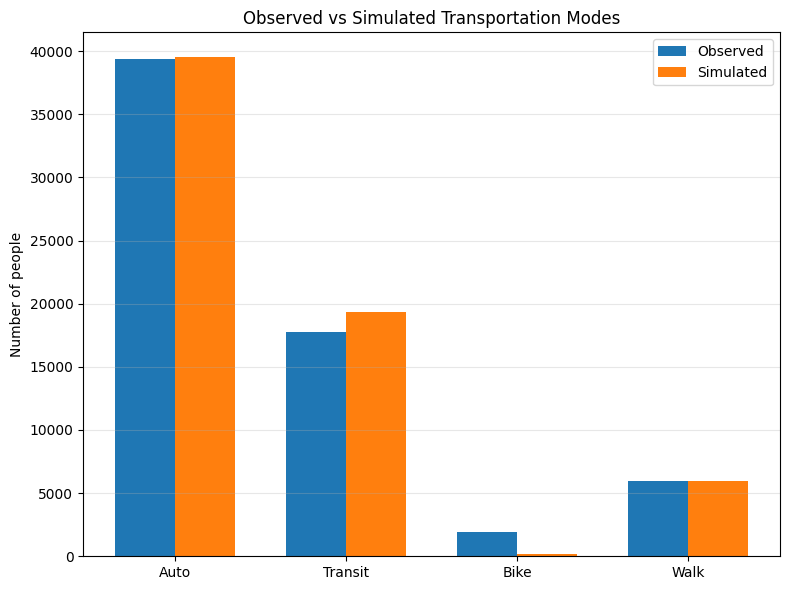


Optimization finished

Best MSE:
0.003942645668989255

Optimized coefficients:
[-1.76626253 -0.99357724  1.32872911  0.4848044  -0.72181407 -0.29698104
 -0.6363704  -0.10502494  1.44367094 -0.74465311 -0.75412724  0.45131746
 -0.71515951 -0.96311305 -0.81134955 -0.74598147 -1.34556375 -1.0820303
  1.36239883 -1.14305278 -0.85510513 -0.51054724 -0.07798161 -1.13691709
  0.51640664 -0.35757058  0.35645632 -0.27178365 -0.63221687  1.58076458
  0.80117826  1.28619747 -4.27768184]


In [14]:
mse_history = []
beta_history = []


def objective(trial):

    Sugg_betas = np.array([

    # =========================================================
    # AUTO
    # =========================================================

    trial.suggest_float("β1", -2.0, -0.05),      # time_auto → NEGATIVE
    trial.suggest_float("β2", -1.5,  0.0),       # age_auto → NEGATIVE
    trial.suggest_float("β3", -1.5,  1.5),       # gender_auto → depends on coding
    trial.suggest_float("β4",  0.0,  1.5),       # income_auto → POSITIVE
    trial.suggest_float("β5", -1.5,  0.0),       # population_density_auto → NEGATIVE

    trial.suggest_float("β6", -1.0,  0.0),       # age × time_auto → NEGATIVE
    trial.suggest_float("β7", -1.0, 0.0),        # income × time_auto → NEGATIVE


    # =========================================================
    # TRANSIT
    # =========================================================

    trial.suggest_float("β8", -2.0, -0.05),      # time_transit → NEGATIVE
    trial.suggest_float("β9",  0.0,  1.5),       # age_transit → POSITIVE
    trial.suggest_float("β10", -1.5, 1.5),       # gender_transit → depends on coding
    trial.suggest_float("β11", -1.5, 0.0),       # income_transit → NEGATIVE
    trial.suggest_float("β12",  0.0, 1.5),       # population_density_transit → POSITIVE

    trial.suggest_float("β13", -1.0, 0.0),       # age × time_transit → NEGATIVE
    trial.suggest_float("β14", -1.0, 0.0),       # income × time_transit → NEGATIVE


    # =========================================================
    # BIKE
    # =========================================================

    trial.suggest_float("β15", -2.0, -0.05),     # time_bike → NEGATIVE
    trial.suggest_float("β16", -1.5,  0.0),      # age_bike → NEGATIVE
    trial.suggest_float("β17", -1.5,  1.5),      # gender_bike → depends on coding
    trial.suggest_float("β18", -1.5,  0.0),      # income_bike → NEGATIVE
    trial.suggest_float("β19",  0.0, 1.5),       # population_density_bike → POSITIVE
    trial.suggest_float("β20", -1.5, -0.01),     # proximity_to_bikelanes → NEGATIVE

    trial.suggest_float("β21", -1.0, 0.0),       # age × time_bike → NEGATIVE
    trial.suggest_float("β22", -1.0, 0.0),       # income × time_bike → NEGATIVE


    # =========================================================
    # WALK
    # =========================================================

    trial.suggest_float("β23", -2.0, -0.05),     # time_walk → NEGATIVE
    trial.suggest_float("β24", -1.5,  0.0),      # age_walk → NEGATIVE
    trial.suggest_float("β25", -1.5,  1.5),      # gender_walk → depends on coding
    trial.suggest_float("β26", -1.5,  0.0),      # income_walk → NEGATIVE
    trial.suggest_float("β27",  0.0, 1.5),       # population_density_walk → POSITIVE

    trial.suggest_float("β28", -1.0, 0.0),       # age × time_walk → NEGATIVE
    trial.suggest_float("β29", -1.0, 0.0),       # income × time_walk → NEGATIVE


    # =========================================================
    # PEER EFFECTS
    # =========================================================

    trial.suggest_float("γ_bike",    0.0, 2.5),  # POSITIVE


    # =========================================================
    # ASCs
    #
    # WALK = REFERENCE ALTERNATIVE
    # ASC_walk = 0
    # =========================================================

    trial.suggest_float("ASC_auto",    -3.0, 3.0),
    trial.suggest_float("ASC_transit", -3.0, 5.0),
    trial.suggest_float("ASC_bike",    -5.0, 3.0)

    ])


    # Run calibration
    mse = calibration_error(betas = Sugg_betas,model = Transport_model,n_steps=5,save_results=False)


    mse_history.append(mse)
    beta_history.append(Sugg_betas.copy())


    print("\n-----------------------------")
    print(f"Trial: {trial.number}")
    print(f"MSE: {mse:.6f}")

    print("Betas:")
    print(Sugg_betas)


    return mse


# ============================================================
# Run Optuna
# ============================================================

study = optuna.create_study(direction="minimize",sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective,n_trials=30)


# ============================================================
# Extract best parameters
# ============================================================

best_params = study.best_params


optimized_betas = np.array([

    # Auto
    best_params["β1"],
    best_params["β2"],
    best_params["β3"],
    best_params["β4"],
    best_params["β5"],
    best_params["β6"],
    best_params["β7"],

    # Transit
    best_params["β8"],
    best_params["β9"],
    best_params["β10"],
    best_params["β11"],
    best_params["β12"],
    best_params["β13"],
    best_params["β14"],

    # Bike
    best_params["β15"],
    best_params["β16"],
    best_params["β17"],
    best_params["β18"],
    best_params["β19"],
    best_params["β20"],
    best_params["β21"],
    best_params["β22"],

    # Walk
    best_params["β23"],
    best_params["β24"],
    best_params["β25"],
    best_params["β26"],
    best_params["β27"],
    best_params["β28"],
    best_params["β29"],


    # Social interaction
    best_params["γ_bike"],

    # ASCs
    best_params["ASC_auto"],
    best_params["ASC_transit"],
    best_params["ASC_bike"]
])


#  CHECK CONVERGENCE OF TRANSPORTATION MODE CHOICES
Transport_model.reset_trial_state()
Transport_model.betas = optimized_betas

previous_modes = None

for step in range(5):

    # First step without social influence
    # Subsequent steps with social influence
    Transport_model.social_interaction = step > 0
    Transport_model.model_step()

    current_modes = np.array([a.mode_choice for a in Transport_model.agent_list], dtype=object)

    if previous_modes is not None:
        changed = np.mean(current_modes != previous_modes)
        print(f"\nStep {step + 1}: " f"{changed * 100:.2f}% of agents changed mode")

    previous_modes = current_modes.copy()


# FINAL CALIBRATION WITH OPTIMIZED PARAMETERS
best_mse = calibration_error(betas = optimized_betas,model =Transport_model,n_steps=5,save_results=True)


print("\n==============================")
print("Optimization finished")
print("==============================")

print("\nBest MSE:")
print(study.best_value)

print("\nOptimized coefficients:")
print(optimized_betas)


# ============================================================
# Save coefficients
# ============================================================

np.save("/content/drive/MyDrive/Transportation_UrbanHealth/Betas_HighComplexity.npy",optimized_betas)

#Randomly changing agents' residential locations and workplaces


========== BASELINE SIMULATION ==========
Execution time for 5 steps: 8.444 seconds
Baseline counts: [39515 19343   202  5956]

Agents selected for relocation: 19504


Relocating agents: 100%|██████████| 19504/19504 [03:34<00:00, 90.88it/s]



Updating local population density...

Recalculating travel times for relocated agents...
[1/4] Computing car travel times...
Done (164.3 s)
[2/4] Computing walking travel times...
Done (223.1 s)
[3/4] Computing STM travel times...
Done (126.0 s)
[4/4] Computing BIKE travel times...
Done (225.5 s)

Updating static calibration data...

========== POST-RELOCATION SIMULATION ==========
Execution time for 5 steps: 8.626 seconds
Post-relocation counts: [39691 19171   213  5941]

========== COMPARISON ==========
      Mode  Before  After  Difference  Before_share  After_share  Change_pp
0     Auto   39515  39691         176         0.608        0.610      0.271
1  Transit   19343  19171        -172         0.298        0.295     -0.265
2     Bike     202    213          11         0.003        0.003      0.017
3     Walk    5956   5941         -15         0.092        0.091     -0.023

Transportation mode transition matrix:
After     auto  transit  bike  walk
Before                          

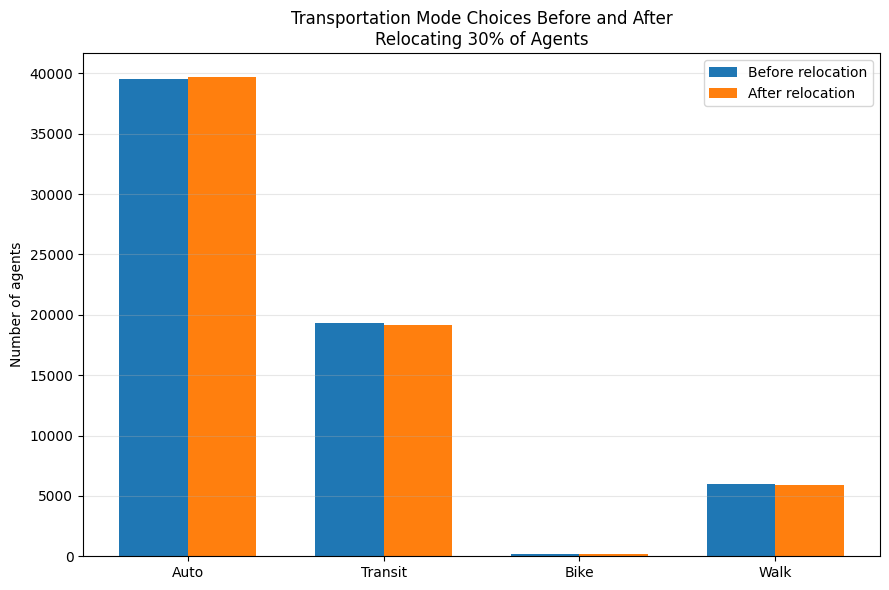

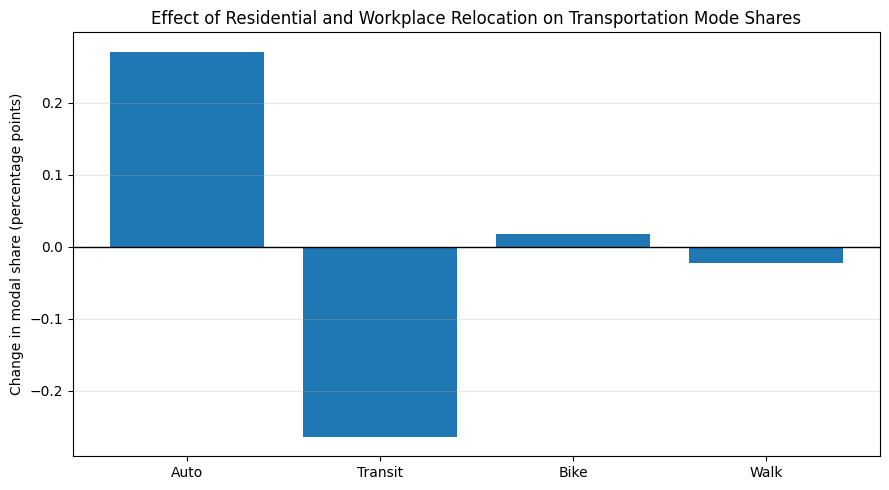

In [15]:
# LOAD OPTIMIZED COEFFICIENTS

Optimized_betas = np.load("/content/drive/MyDrive/Transportation_UrbanHealth/Betas_HighComplexity.npy")

Transport_model.betas = Optimized_betas

agents = Transport_model.agent_list
n_agents = len(agents)

modes = ["auto", "transit", "bike", "walk"]
mode_labels = ["Auto", "Transit", "Bike", "Walk"]

# HELPER FUNCTION: RUN FIVE SIMULATION STEPS

def run_transport_simulation(model, betas, n_steps=5):

    model.reset_trial_state()
    model.betas = betas

    start = time.perf_counter()

    for step in range(n_steps):

        # First step without social interaction
        # Subsequent steps with social interaction
        model.social_interaction = step > 0

        # Explicitly call custom TransportModel.step()
        TransportModel.model_step(model)

    elapsed = time.perf_counter() - start

    print(f"Execution time for {n_steps} steps: {elapsed:.3f} seconds")

    return np.array([a.mode_choice for a in model.agent_list],dtype=object)


# BASELINE SIMULATION BEFORE RELOCATION


print("\n========== BASELINE SIMULATION ==========")
baseline_choices = run_transport_simulation(Transport_model,Optimized_betas,n_steps=5)

baseline_counts = np.array([np.sum(baseline_choices == mode) for mode in modes])

print("Baseline counts:", baseline_counts)

# RANDOMLY SELECT 30% OF AGENTS

sample_size = int(0.30 * n_agents)
selected_indices = random.sample(range(n_agents), sample_size)
selected_agents = [agents[i] for i in selected_indices]
selected_indices_set = set(selected_indices)
print("\nAgents selected for relocation:", sample_size)


# CHANGE RESIDENTIAL AND WORKPLACE LOCATIONS

# Store original locations
original_locations = {
    i: {
        "res_id": agents[i].res_id,
        "work_id": agents[i].work_id,
        "x": agents[i].x,
        "y": agents[i].y,
        "work_x": agents[i].work_x,
        "work_y": agents[i].work_y
    }
    for i in selected_indices
}

# Keep residential choices restricted to valid residential locations
residential_ids = Transport_model.residential["res_id"].to_numpy()

for i in tqdm(selected_indices,desc="Relocating agents"):

    agent = agents[i]
    old_res_id = agent.res_id

    # Select a different residential location
    # (provided at least two residences exist)
    if len(residential_ids) > 1:
        new_res_id = old_res_id
        while new_res_id == old_res_id:
            new_res_id = random.choice(residential_ids)
    else:
        new_res_id = old_res_id

    agent.res_id = new_res_id


    agent.work_id = None
    agent.work_x = np.nan
    agent.work_y = np.nan

    agent.workplace_node_network = None
    agent.work_stm_node_network = None

    # Assign new home and workplace
    agent.assign_nodes()


# UPDATE LOCAL POPULATION DENSITY

print("\nUpdating local population density...")
Transport_model.assign_local_population_density()


# RECALCULATE TRAVEL TIMES FOR RELOCATED AGENTS

print("\nRecalculating travel times for relocated agents...")

# Reset travel times and availability flags
for agent in selected_agents:

    agent.time_car = np.nan
    agent.time_home_stm = np.nan
    agent.time_stm_stm = np.nan
    agent.time_stm_work = np.nan
    agent.time_bike = np.nan
    agent.time_walk = np.nan

    agent.auto_available = False
    agent.transit_available = False
    agent.bike_available = False
    agent.walk_available = False

# Calculate only once, not inside the five-step loop
Transport_model.compute_all_travel_times(selected_agents)


# UPDATE STATIC CALIBRATION DATA

print("\nUpdating static calibration data...")
Transport_model.prepare_static_calibration_data()


# RUN POST-RELOCATION SIMULATION

print("\n========== POST-RELOCATION SIMULATION ==========")

new_choices = run_transport_simulation(Transport_model,Optimized_betas,n_steps=5)

new_counts = np.array([np.sum(new_choices == mode)for mode in modes])
print("Post-relocation counts:", new_counts)


# COMPARE BEFORE AND AFTER

print("\n========== COMPARISON ==========")

comparison_df = pd.DataFrame({
    "Mode": mode_labels,
    "Before": baseline_counts,
    "After": new_counts,
    "Difference": new_counts - baseline_counts,
    "Before_share": baseline_counts / n_agents,
    "After_share": new_counts / n_agents
})

comparison_df["Change_pp"] = (comparison_df["After_share"]- comparison_df["Before_share"]) * 100
print(comparison_df.round(3))


# INDIVIDUAL TRANSPORTATION MODE TRANSITIONS

transition_df = pd.crosstab(
    pd.Categorical(baseline_choices, categories=modes),
    pd.Categorical(new_choices, categories=modes),
    rownames=["Before"],
    colnames=["After"],
    dropna=False
)

print("\nTransportation mode transition matrix:")
print(transition_df)

# Total number of agents who changed transportation mode
changed_modes = baseline_choices != new_choices

print("\nAgents changing transportation mode:",changed_modes.sum())
print("Percentage changing transportation mode:",round(changed_modes.mean() * 100, 2),"%")


# SEPARATE RELOCATED AND NON-RELOCATED AGENTS

relocated_mask = np.zeros(n_agents, dtype=bool)
relocated_mask[selected_indices] = True

relocated_changed = np.sum(changed_modes & relocated_mask)

non_relocated_changed = np.sum(changed_modes & ~relocated_mask)

print("\nRelocated agents changing mode:", relocated_changed)
print("Percentage of relocated agents changing mode:",round(relocated_changed / sample_size * 100, 2),"%")
print("\nNon-relocated agents changing mode:",non_relocated_changed)
print("Percentage of non-relocated agents changing mode:",round(non_relocated_changed/ (n_agents - sample_size) * 100,2),"%")

# PLOT BEFORE VS AFTER TRANSPORTATION MODE COUNTS

x = np.arange(len(modes))
width = 0.35

plt.figure(figsize=(9, 6))

plt.bar(
    x - width / 2,
    baseline_counts,
    width,
    label="Before relocation"
)

plt.bar(
    x + width / 2,
    new_counts,
    width,
    label="After relocation"
)

plt.xticks(x, mode_labels)

plt.ylabel("Number of agents")

plt.title(
    "Transportation Mode Choices Before and After\n"
    "Relocating 30% of Agents"
)

plt.grid(axis="y", alpha=0.3)

plt.legend()
plt.tight_layout()
plt.show()


# PLOT CHANGE IN MODAL SHARES

plt.figure(figsize=(9, 5))

plt.bar(mode_labels,comparison_df["Change_pp"])
plt.axhline(0, color="black", linewidth=1)
plt.ylabel("Change in modal share (percentage points)")
plt.title("Effect of Residential and Workplace Relocation on Transportation Mode Shares")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()